# Feature Extraction VGG16

Tämä notebook toteuttaa Feature Extraction mallin.
Data, jako ja esikäsittely ovat samat kuin CNN-notebookissa.
Tässä notebookissa keskitytään Modeling- ja Evaluation-vaiheisiin.

## 2. Data ja esikäsittely

Sama data ja jako kuin CNN-notebookissa. Kuvakoko 224×224.

## 2.1 Datan jakaminen

Kuvat jaetaan harjoitus-, validointi- ja testijoukkoon suhteessa 70/15/15. Käytetään samaa siementä, jotta jako on toistettavissa.

In [1]:
from pathlib import Path
import random
import shutil
import keras
keras.utils.set_random_seed(42)

SEED = 0
rng = random.Random(SEED)

source = Path("sormenjalkitunnistin/kuvat")  
target = Path("dataset_split")

if target.exists():
    shutil.rmtree(target)

target.mkdir(parents=True, exist_ok=True)

for class_dir in sorted(source.iterdir()):
    if not class_dir.is_dir():
        continue

    images = sorted(
        p for p in class_dir.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )

    rng.shuffle(images)

    n = len(images)
    n_train = int(n * 0.70)
    n_val = int(n * 0.15)

    splits = {
        "train": images[:n_train],
        "val": images[n_train:n_train + n_val],
        "test": images[n_train + n_val:]
    }

    for split, files in splits.items():
        output_dir = target / split / class_dir.name
        output_dir.mkdir(parents=True, exist_ok=True)

        for file in files:
            shutil.copy2(file, output_dir / file.name)

        print(f"{class_dir.name} | {split}: {len(files)}")

0 | train: 280
0 | val: 60
0 | test: 61
1 | train: 322
1 | val: 69
1 | test: 70
2 | train: 331
2 | val: 71
2 | test: 72
3 | train: 375
3 | val: 80
3 | test: 81
4 | train: 229
4 | val: 49
4 | test: 50
5 | train: 319
5 | val: 68
5 | test: 69


## 2.2 Datan lataus

Kuvat ladataan Kerasin image_dataset_from_directory-funktiolla ja skaalataan 224×224-kokoon. Validointi- ja testijoukossa järjestystä ei sekoiteta, jotta ennusteet voidaan myöhemmin yhdistää oikeisiin kuviin.

In [2]:
import keras
from keras import layers
from keras.utils import image_dataset_from_directory

train_dataset = image_dataset_from_directory(
    "dataset_split/train",
    image_size=(224, 224),
    batch_size=32)

validation_dataset = image_dataset_from_directory(
    "dataset_split/val",
    image_size=(224, 224),
    batch_size=32,
    shuffle=False)              

test_dataset = image_dataset_from_directory(
    "dataset_split/test",
    image_size=(224, 224),
    batch_size=32,
    shuffle=False)               

class_names = train_dataset.class_names
num_classes = len(class_names)
print(f"Classes: {class_names}")

Found 1856 files belonging to 6 classes.
Found 397 files belonging to 6 classes.
Found 403 files belonging to 6 classes.
Classes: ['0', '1', '2', '3', '4', '5']


## 3. Mallintaminen

### 3.1 Mallin rakentaminen

Pohjaksi otetaan VGG16 ilman yläluokittelijaa, ImageNet-painoilla ja lukittuna. Päälle rakennetaan yksinkertainen luokittelija: GlobalAveragePooling2D tiivistää piirteet, Dropout(0.3) estää ylisovitusta ja Dense-kerros ennustaa kuusi luokkaa. Koulutettavia parametreja on vain 3078, koska VGG16 pysyy lukittuna.

In [3]:
from keras.applications import VGG16
from keras.applications.vgg16 import preprocess_input

# Esikoulutettu pohja ilman omaa luokittelijaa, ImageNet-painot, lukittu
base = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3),
)
base.trainable = False

# Syöte ja VGG16:n oma esikäsittely
inputs = keras.Input(shape=(224, 224, 3))
x = preprocess_input(inputs)

# Piirteet pohjasta
x = base(x, training=False)

# Oma luokittelija
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

model_fe = keras.Model(inputs, outputs)
model_fe.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)    │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item (GetItem)            │ (None, 224, 224)          │               0 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item_1 (GetItem)          │ (None, 224, 224)          │               0 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item_2 (GetItem)          │ (None, 224, 224)          │               0 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stack (Stack)                 │ (None, 224, 224, 3)       │               0 │ get_item[0][0],            │
│                               │                           │                 │ get_item_1[0][0],          │
│                               │                           │                 │ get_item_2[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 224, 224, 3)       │               0 │ stack[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ vgg16 (Functional)            │ (None, 7, 7, 512)         │      14,714,688 │ add[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ global_average_pooling2d      │ (None, 512)               │               0 │ vgg16[0][0]                │
│ (GlobalAveragePooling2D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout (Dropout)             │ (None, 512)               │               0 │ global_average_pooling2d[… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 6)                 │           3,078 │ dropout[0][0]              │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 14,717,766 (56.14 MB)

 Trainable params: 3,078 (12.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

### 3.2 Kokoaminen

Malli kootaan Adam-optimointimenetelmällä ja sparse categorical crossentropy häviöfunktiolla.

In [4]:
model_fe.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

### 3.3 Koulutus

Mallia koulutetaan 30 epochia. Koulutuksen jälkeen painot tallennetaan tiedostoon, jota käytetään myöhemmin fine-tuningissa.

In [5]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
    ),
]

history_fe = model_fe.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=30,
    verbose=2,
    callbacks=callbacks,
)

model_fe.save_weights("fe_vgg16.weights.h5")
print("Painot tallennettu: fe_vgg16.weights.h5")

Epoch 1/30


C:\Users\sakar\anaconda3\envs\nn\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


58/58 - 270s - 5s/step - accuracy: 0.2635 - loss: 2.3838 - val_accuracy: 0.4181 - val_loss: 1.4271
Epoch 2/30
58/58 - 278s - 5s/step - accuracy: 0.4111 - loss: 1.6171 - val_accuracy: 0.5793 - val_loss: 1.0865
Epoch 3/30
58/58 - 252s - 4s/step - accuracy: 0.5189 - loss: 1.2236 - val_accuracy: 0.6650 - val_loss: 0.9172
Epoch 4/30
58/58 - 248s - 4s/step - accuracy: 0.6002 - loss: 1.0411 - val_accuracy: 0.7254 - val_loss: 0.8000
Epoch 5/30
58/58 - 247s - 4s/step - accuracy: 0.6439 - loss: 0.9164 - val_accuracy: 0.7657 - val_loss: 0.7272
Epoch 6/30
58/58 - 247s - 4s/step - accuracy: 0.6751 - loss: 0.8482 - val_accuracy: 0.7733 - val_loss: 0.6774
Epoch 7/30
58/58 - 255s - 4s/step - accuracy: 0.7214 - loss: 0.7454 - val_accuracy: 0.7859 - val_loss: 0.6307
Epoch 8/30
58/58 - 247s - 4s/step - accuracy: 0.7333 - loss: 0.7097 - val_accuracy: 0.7960 - val_loss: 0.5974
Epoch 9/30
58/58 - 246s - 4s/step - accuracy: 0.7381 - loss: 0.6831 - val_accuracy: 0.8086 - val_loss: 0.5748
Epoch 10/30
58/58 - 2

## 4. Arviointi

### 4.1 Testiarviointi

Mallin suorituskyky arvioidaan testijoukolla, jota ei ole käytetty koulutuksessa.

In [6]:
test_loss, test_accuracy = model_fe.evaluate(test_dataset)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

13/13 ━━━━━━━━━━━━━━━━━━━━ 45s 3s/step - accuracy: 0.8859 - loss: 0.3863
Test Loss: 0.3862919509410858
Test Accuracy: 0.8858560919761658


Testitarkkuus 88.59 % tarkoittaa, että malli tunnistaa 357 kuvaa 403:sta oikein eli 46 kuvaa menee väärin. Testihäviö on 0.3863. Tämä on kohtuullinen tulos ottaen huomioon, että vain 3 078 parametria on koulutettu ja VGG16:n ImageNet-piirteet eivät ole optimaalisia sormikuville.

### 4.2 Oppimiskäyrät

Piirretään loss ja accuracy sekä harjoitus- että validointidatalle. Käyristä näkee, onko malli ylikouluttunut vai oppinut tasaisesti.

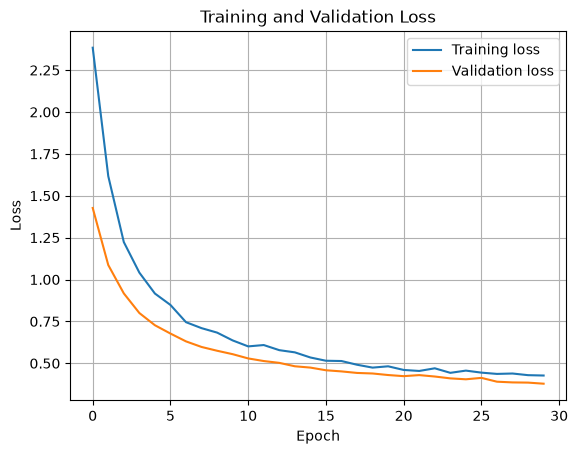

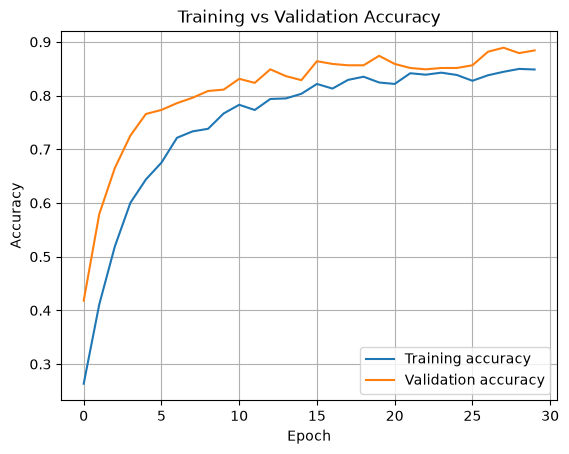

In [7]:
import matplotlib.pyplot as plt

plt.plot(history_fe.history["loss"], label="Training loss")
plt.plot(history_fe.history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.plot(history_fe.history["accuracy"], label="Training accuracy")
plt.plot(history_fe.history["val_accuracy"], label="Validation accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

Käyristä näkee, että train- ja validation-käyrät seuraavat toisiaan eivätkä erkane merkittävästi. Malli ei siis ylikouluttunut pahasti 30 epochin aikana. Validointitarkkuus tasaantuu loppua kohden, mikä viittaa siihen, että pidempi koulutus ei enää toisi merkittävää parannusta.

### 4.3 Ennusteet testijoukolla

Ajetaan malli läpi testidatasta ja kerätään ennusteet talteen. Näitä käytetään seuraavissa vaiheissa sekaannusmatriisiin ja virheanalyysiin.

In [8]:
import numpy as np
import matplotlib.pyplot as plt

all_probs = []
all_true = []
all_images = []

for images, labels in test_dataset:
    probs = model_fe.predict(images, verbose=0)
    all_probs.append(probs)
    all_true.append(labels.numpy())
    all_images.append(images.numpy())

y_probs = np.concatenate(all_probs)
y_true = np.concatenate(all_true)
y_pred = np.argmax(y_probs, axis=1)
x_test = np.concatenate(all_images)

print(f"Kuvia: {len(y_true)}")
print(f"Oikein: {np.sum(y_true == y_pred)} / {len(y_true)}")
print(f"Test accuracy: {np.mean(y_true == y_pred) * 100:.2f}%")

Kuvia: 403
Oikein: 357 / 403
Test accuracy: 88.59%


### 4.4 Confusion matrix

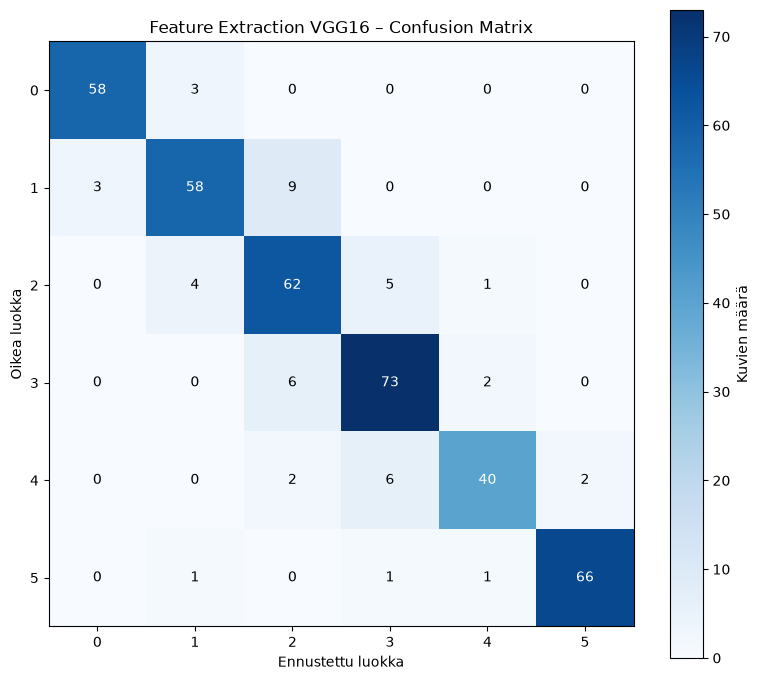

In [9]:
cm = np.zeros((num_classes, num_classes), dtype=int)

for true, pred in zip(y_true, y_pred):
    cm[true, pred] += 1

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap="Blues")

ax.set_xticks(np.arange(num_classes))
ax.set_yticks(np.arange(num_classes))
ax.set_xticklabels(class_names)
ax.set_yticklabels(class_names)

ax.set_xlabel("Ennustettu luokka")
ax.set_ylabel("Oikea luokka")
ax.set_title("Feature Extraction VGG16 – Confusion Matrix")
fig.colorbar(im, ax=ax, label="Kuvien määrä")

for i in range(num_classes):
    for j in range(num_classes):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black"
        )

plt.tight_layout()
plt.show()

Diagonaali on vahva kaikilla luokilla. Selvimmin virheet keskittyvät vierekkäisiin luokkiin: luokat 1 ja 2 sekoittuvat keskenään (13 tapausta) ja luokat 2 ja 3 keskenään (11 tapausta). Myös luokat 3 ja 4 sekoittuvat (8 tapausta). Luokka 0 ei sekoitu käytännössä lainkaan muihin luokkiin (vain 3 tapausta luokkaan 1).

### 4.5 Luokkakohtainen tarkkuus

Lasketaan, kuinka monta prosenttia kustakin luokasta meni oikein. Tämä auttaa tunnistamaan heikoimmat luokat.

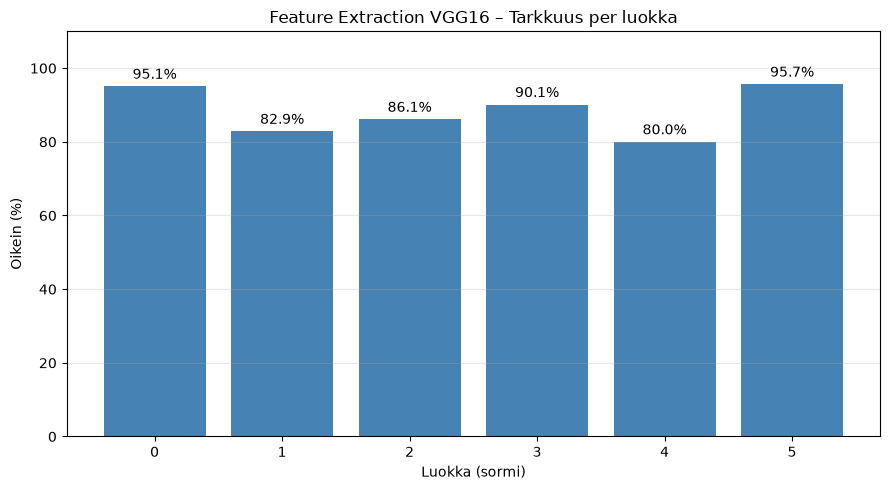


Luokka | Oikein | Yhteensä | Tarkkuus
---------------------------------------------
     0  |    58  |     61   |   95.1%
     1  |    58  |     70   |   82.9%
     2  |    62  |     72   |   86.1%
     3  |    73  |     81   |   90.1%
     4  |    40  |     50   |   80.0%
     5  |    66  |     69   |   95.7%


In [10]:
correct = np.zeros(num_classes, dtype=int)
total = np.zeros(num_classes, dtype=int)

for i in range(num_classes):
    mask = (y_true == i)
    total[i] = np.sum(mask)
    correct[i] = np.sum(y_pred[mask] == i)

accuracy = np.divide(
    correct, total,
    out=np.zeros(num_classes, dtype=float),
    where=total != 0
) * 100

plt.figure(figsize=(9, 5))
bars = plt.bar(class_names, accuracy, color="steelblue")
plt.bar_label(bars, fmt="%.1f%%", padding=3)

plt.xlabel("Luokka (sormi)")
plt.ylabel("Oikein (%)")
plt.title("Feature Extraction VGG16 – Tarkkuus per luokka")
plt.ylim(0, 110)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nLuokka | Oikein | Yhteensä | Tarkkuus")
print("-" * 45)
for i in range(num_classes):
    print(f"  {class_names[i]:>4}  |  {correct[i]:>4}  |   {total[i]:>4}   |  {accuracy[i]:>5.1f}%")

Heikoimmat luokat ovat 4 (80.0 %) ja 1 (82.9 %). Sekaannusmatriisista näkee, että virheet menevät pääosin vierekkäisiin sormimääriin: 1 sormi sekoittuu useimmin 2 sormeen (9 tapausta), ja 4 sormea sekoittuu 3 sormeen (6 tapausta). Tämä on odotettua, koska yhden sormen erottaminen on vaikeaa, kun sormet ovat lähekkäin tai osittain koukussa. Luokka 0 tunnistetaan lähes täydellisesti (95.1 %, 58/61), koska se on visuaalisesti selvästi erilainen kuin avoimet kädet.

### 4.6 Väärin luokitellut kuvat

Näytetään satunnaisotos väärin luokitelluista kuvista. Kuvista näkee, menevätkö virheet vierekkäisiin luokkiin, mikä olisi odotettua.

Väärin luokiteltuja: 46 / 403


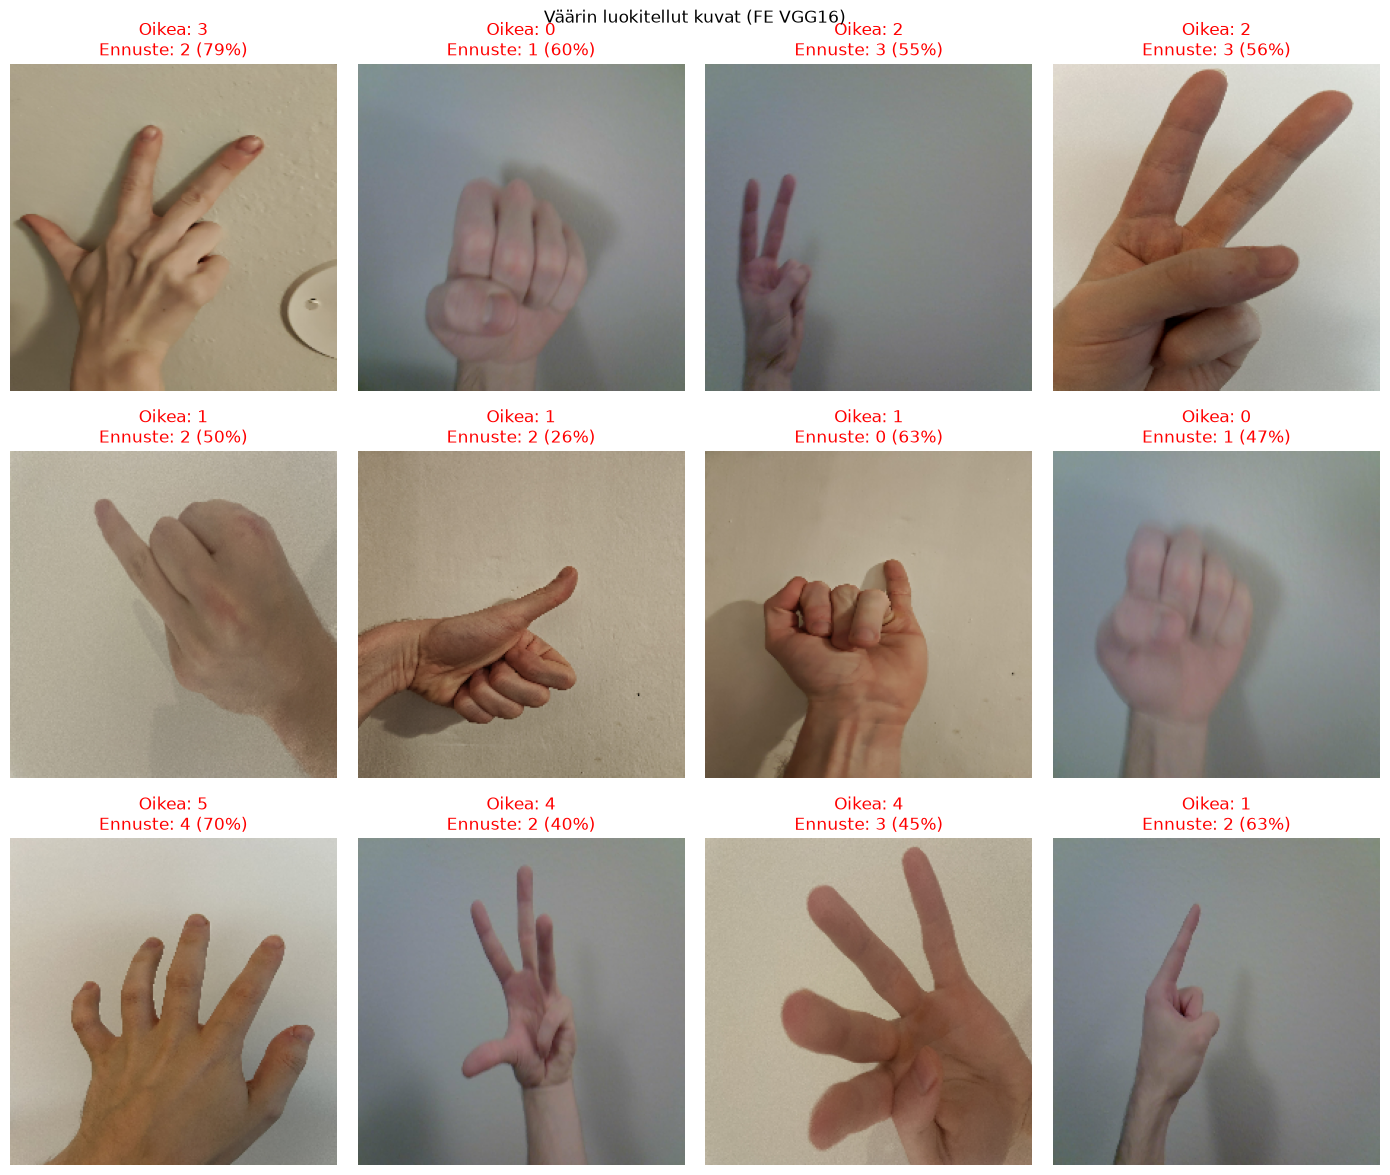

In [11]:
wrong_idx = np.where(y_true != y_pred)[0]
print(f"Väärin luokiteltuja: {len(wrong_idx)} / {len(y_true)}")

rng = np.random.default_rng(0)
show_idx = rng.choice(wrong_idx, size=min(12, len(wrong_idx)), replace=False)

n_cols = 4
n_rows = (len(show_idx) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
axes = axes.flatten()

for i, idx in enumerate(show_idx):
    ax = axes[i]
    ax.imshow(x_test[idx].astype("uint8"))

    true_class = int(y_true[idx])
    pred_class = int(y_pred[idx])
    conf = y_probs[idx][pred_class]

    ax.set_title(
        f"Oikea: {class_names[true_class]}\n"
        f"Ennuste: {class_names[pred_class]} ({conf:.0%})",
        color="red"
    )
    ax.axis("off")

for j in range(len(show_idx), len(axes)):
    axes[j].axis("off")

plt.suptitle("Väärin luokitellut kuvat (FE VGG16)")
plt.tight_layout(h_pad=3.0, w_pad=1.5)
plt.show()

Väärin luokitelluista kuvista huomaa: virheet keskittyvät tapauksiin, joissa sormien määrä on lähellä toista esim 2 ja 3 tai 3 ja 4. Myös kätisyyden vaihtelu lisää variaatiota.

### 4.7 Yksittäisen kuvan ennuste

Näytetään kolme satunnaista testikuvaa ja niiden ennustetodennäköisyydet. 

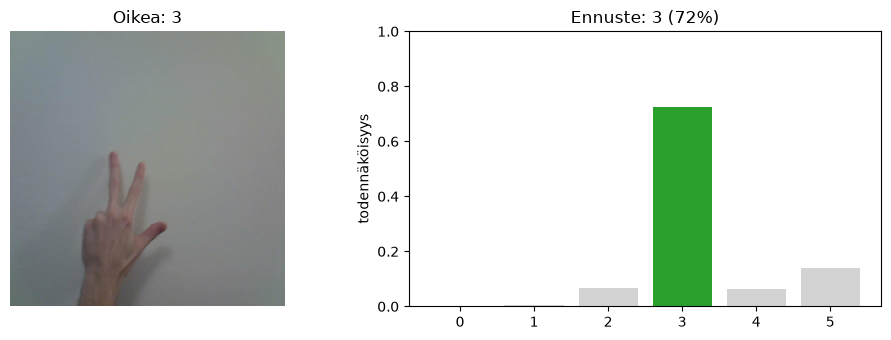

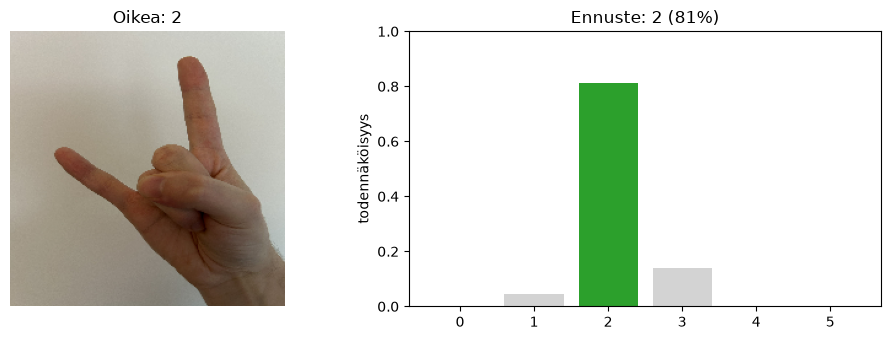

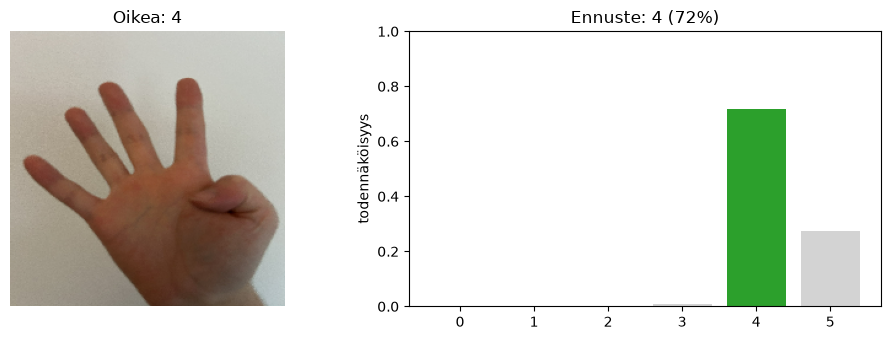

In [12]:
def plot_prediction(idx):
    pred = int(y_pred[idx])
    true = int(y_true[idx])

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))

    ax1.imshow(x_test[idx].astype("uint8"))
    ax1.axis("off")
    ax1.set_title(f"Oikea: {class_names[true]}")

    colors = ["lightgray"] * num_classes
    colors[pred] = "tab:red" if pred != true else "tab:green"
    ax2.bar(range(num_classes), y_probs[idx], color=colors)
    ax2.set_xticks(range(num_classes))
    ax2.set_xticklabels(class_names, rotation=0)
    ax2.set_ylim(0, 1)
    ax2.set_ylabel("todennäköisyys")
    ax2.set_title(f"Ennuste: {class_names[pred]} ({y_probs[idx][pred]:.0%})")

    plt.tight_layout()
    plt.show()

# Näytetään 3 satunnaista testikuvaa
rng2 = np.random.default_rng(1)
for idx in rng2.choice(len(y_true), size=3, replace=False):
    plot_prediction(idx)

Esimerkkien ennustetodennäköisyydet olivat 72 %, 81 % ja 72 %, ja ennusteet osuivat luokkiin 3, 2 ja 4. Erityisesti 72 %:n tapaukset osoittavat, että FE-malli on epävarma.

### 4.8 Classification report

Yhteenveto per luokka: precision, recall ja F1-score.

In [13]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true, y_pred,
    target_names=class_names,
    digits=4
))

              precision    recall  f1-score   support

           0     0.9508    0.9508    0.9508        61
           1     0.8788    0.8286    0.8529        70
           2     0.7848    0.8611    0.8212        72
           3     0.8588    0.9012    0.8795        81
           4     0.9091    0.8000    0.8511        50
           5     0.9706    0.9565    0.9635        69

    accuracy                         0.8859       403
   macro avg     0.8922    0.8830    0.8865       403
weighted avg     0.8884    0.8859    0.8861       403



Luokkien 0 ja 5 precision ja recall ovat erittäin korkeat. Heikoimmat F1-arvot ovat luokilla 2 (0.8212) ja 4 (0.8511), mikä vastaa aiempia havaintoja: virheet keskittyvät vierekkäisiin sormimääriin.

## Tulosten tallennus

In [14]:
import json
import pandas as pd

metrics_fe = {
    "model": "feature_extraction_vgg16",
    "image_size": 224,
    "class_names": list(class_names),
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "confusion_matrix": cm.tolist(),
    "per_class_accuracy": accuracy.tolist(),
    "per_class_correct": correct.tolist(),
    "per_class_total": total.tolist(),
}
with open("metrics_fe.json", "w") as f:
    json.dump(metrics_fe, f, indent=2)

pd.DataFrame(history_fe.history).to_csv("history_fe.csv", index=False)

np.savez(
    "test_predictions_fe.npz",
    y_true=y_true,
    y_pred=y_pred,
    y_probs=y_probs,
)

print("Tallennettu: metrics_fe.json, history_fe.csv, test_predictions_fe.npz")

Tallennettu: metrics_fe.json, history_fe.csv, test_predictions_fe.npz


Feature Extraction -malli saavutti 88.59 % testitarkkuuden. Tulos toimii lähtötasona fine-tuning-mallille: kun VGG16:n ylin konvoluutioblokki avataan, mallin pitäisi oppia käsikuvakohtaiset piirteet ja parantaa erityisesti luokkia 2 ja 4, joissa virheet keskittyvät vierekkäisiin sormimääriin.